In [33]:
import builtins
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fftn, ifftn, fftshift, ifftshift
from skimage.metrics import structural_similarity as ssim

images_filepath = Path('.\\MRI\\HCP_selected_ones2.npy')
with builtins.open(images_filepath, 'rb') as f:
    images = np.load(f, allow_pickle=True).astype(np.float32)
n_case_images = min(11_000, images.shape[0])
images = images[:n_case_images]
print('Original images shape:', images.shape)

images_lesion_indices_filepath = Path('.\\MRI\\images_lesion_indices.bin')
with builtins.open(images_lesion_indices_filepath, 'rb') as f:
    lesion_indices_all = np.fromfile(f, dtype=np.int16).reshape(-1, 2)
images_lesion_indices = lesion_indices_all[:n_case_images]
print('Lesion-center indices shape:', images_lesion_indices.shape)

mask_2x_filepath = Path('.\\MRI\\mask_2x_cartesian_for_260x311.npy')
with builtins.open(mask_2x_filepath, 'rb') as f:
    mask_2x = np.load(f, allow_pickle=True)
print('x2 mask shape:', mask_2x.shape)

mask_4x_filepath = Path('.\\MRI\\mask_4x_cartesian_for_260x311.npy')
with builtins.open(mask_4x_filepath, 'rb') as f:
    mask_4x = np.load(f, allow_pickle=True)
print('x4 mask shape:', mask_4x.shape)

reference_lesion_intensity = 0.10
reference_noise_level = 0.10
reference_undersampling_factor = 2
lesion_intensity_cases = [0.05, 0.10, 0.20]
noise_levels = [0.00, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40]
undersampling_factors = [1, 2, 4]
save_reconstructed_images = True
save_iq_metrics = True
random_seed = 0
preview_case_index = 0
preview_source_mode = 'lesion'
preview_noise_level = 0.00
preview_undersampling_factor = 1

sampling_masks = {
    1: np.ones(images.shape[1:], dtype=np.float32),
    2: mask_2x.astype(np.float32),
    4: mask_4x.astype(np.float32),
}

def build_source_tag(source_mode, lesion_intensity):
    if source_mode == 'original':
        return 'original'
    if lesion_intensity is None:
        raise ValueError('lesion_intensity is required when source_mode is lesion.')
    return f'lesion_{lesion_intensity:.2f}'

def build_case_label(source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return (
        f'source={source_tag}, noise={noise_level:.2f}, '
        f'undersampling={undersampling_factor}x'
    )

def build_lesioned_volume_filepath(lesion_intensity):
    if np.isclose(lesion_intensity, reference_lesion_intensity):
        return Path('.\\MRI\\images_lesioned.bin')
    return Path(f'.\\MRI\\images_lesioned_intensity_{lesion_intensity:.2f}.bin')

def build_reconstructed_filepath(source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return Path(
        f'.\\MRI\\images_reconstructed_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.bin'
    )

def build_iq_metrics_filepath(source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return Path(
        f'.\\MRI\\iq_metrics_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.npz'
    )

def load_raw_volume(filepath, shape):
    with builtins.open(filepath, 'rb') as f:
        flat_data = np.fromfile(f, dtype=np.float32)
    expected_size = int(np.prod(shape))
    if flat_data.size < expected_size:
        raise ValueError(f'Volume {filepath} is smaller than expected for shape {shape}.')
    if flat_data.size > expected_size:
        flat_data = flat_data[:expected_size]
    return flat_data.reshape(shape)

def load_source_images(source_mode, lesion_intensity):
    if source_mode == 'original':
        return images.copy()
    filepath = build_lesioned_volume_filepath(lesion_intensity)
    return load_raw_volume(filepath, images.shape)

def build_source_image(case_index, source_mode, lesion_intensity):
    if source_mode == 'original':
        return images[case_index]
    source_images = load_source_images(source_mode, lesion_intensity)
    return source_images[case_index]

def noise_level_to_raw_kspace_component_sigma(noise_level):
    return float(noise_level * np.sqrt(np.prod(images.shape[1:]) / 2.0))

def reconstruct_from_kspace(source_image, noise_level, undersampling_factor, rng):
    shifted_kspace = fftshift(fftn(source_image))
    raw_sigma = noise_level_to_raw_kspace_component_sigma(noise_level)
    if raw_sigma > 0:
        real_noise = rng.normal(loc=0.0, scale=raw_sigma, size=shifted_kspace.shape)
        imag_noise = rng.normal(loc=0.0, scale=raw_sigma, size=shifted_kspace.shape)
        shifted_kspace = shifted_kspace + (real_noise + 1j * imag_noise)
    sampled_shifted_kspace = shifted_kspace * sampling_masks[undersampling_factor]
    reconstructed_image = np.abs(ifftn(ifftshift(sampled_shifted_kspace))).astype(np.float32)
    return reconstructed_image, sampled_shifted_kspace

def compute_image_quality_metrics(reference_images, reconstructed_images):
    mse_values = ((reference_images - reconstructed_images) ** 2).mean(axis=(1, 2))
    ssim_values = np.array([
        ssim(
            reference_images[idx],
            reconstructed_images[idx],
            data_range=float(reference_images[idx].max() - reference_images[idx].min() + 1e-8),
        )
        for idx in range(reference_images.shape[0])
    ], dtype=np.float32)
    return {
        'mse_mean': float(mse_values.mean()),
        'mse_std': float(mse_values.std()),
        'ssim_mean': float(ssim_values.mean()),
        'ssim_std': float(ssim_values.std()),
        'n_images': int(reference_images.shape[0]),
    }

def build_generation_cases():
    cases = []
    for undersampling_factor in undersampling_factors:
        cases.append({
            'source_mode': 'original',
            'lesion_intensity': None,
            'noise_level': 0.00,
            'undersampling_factor': undersampling_factor,
        })
    for noise_level in noise_levels:
        cases.append({
            'source_mode': 'lesion',
            'lesion_intensity': reference_lesion_intensity,
            'noise_level': noise_level,
            'undersampling_factor': reference_undersampling_factor,
        })
    for lesion_intensity in lesion_intensity_cases:
        if np.isclose(lesion_intensity, reference_lesion_intensity):
            continue
        cases.append({
            'source_mode': 'lesion',
            'lesion_intensity': lesion_intensity,
            'noise_level': reference_noise_level,
            'undersampling_factor': reference_undersampling_factor,
        })
    return cases

generation_cases = build_generation_cases()
print('Current source tag:', build_source_tag(preview_source_mode, reference_lesion_intensity))
print('Configured reconstruction/IQ cases:', len(generation_cases))

Original images shape: (11000, 260, 311)
Lesion-center indices shape: (11000, 2)
x2 mask shape: (260, 311)
x4 mask shape: (260, 311)
Current source tag: lesion_0.10
Configured reconstruction/IQ cases: 12


In [32]:
image_i = 0
image = build_source_image(image_i, source_mode, lesion_intensity)
recon_outputs = reconstruct_from_kspace(
    image,
    noise_level=noise_level,
    undersample_factor=undersample_factor,
    rng=np.random.default_rng(random_seed),
)

mask = recon_outputs['sampling_mask']
imagek = recon_outputs['imagek']
noisek = recon_outputs['noisek']
imagek_noised = recon_outputs['imagek_noised']
imagek_noised_shifted = recon_outputs['imagek_noised_shifted']
imagek_noised_shifted_masked = recon_outputs['imagek_noised_shifted_masked']
imagek_noised_masked = recon_outputs['imagek_noised_masked']
image_undersampled_complex = recon_outputs['image_undersampled_complex']
image_undersampled = recon_outputs['image_undersampled']

current_reconstructed_filepath = build_reconstructed_filepath(
    source_mode,
    lesion_intensity,
    noise_level,
    undersample_factor,
)
current_iq_metrics_filepath = build_iq_metrics_filepath(
    source_mode,
    lesion_intensity,
    noise_level,
    undersample_factor,
)
print('Preview reconstructed image file:', current_reconstructed_filepath)
print('Preview IQ metrics file:', current_iq_metrics_filepath)

Preview reconstructed image file: .\MRI\images_reconstructed_source_lesion_0.10_noise_0.00_undersample_1.bin
Preview IQ metrics file: .\MRI\iq_metrics_source_lesion_0.10_noise_0.00_undersample_1.npz


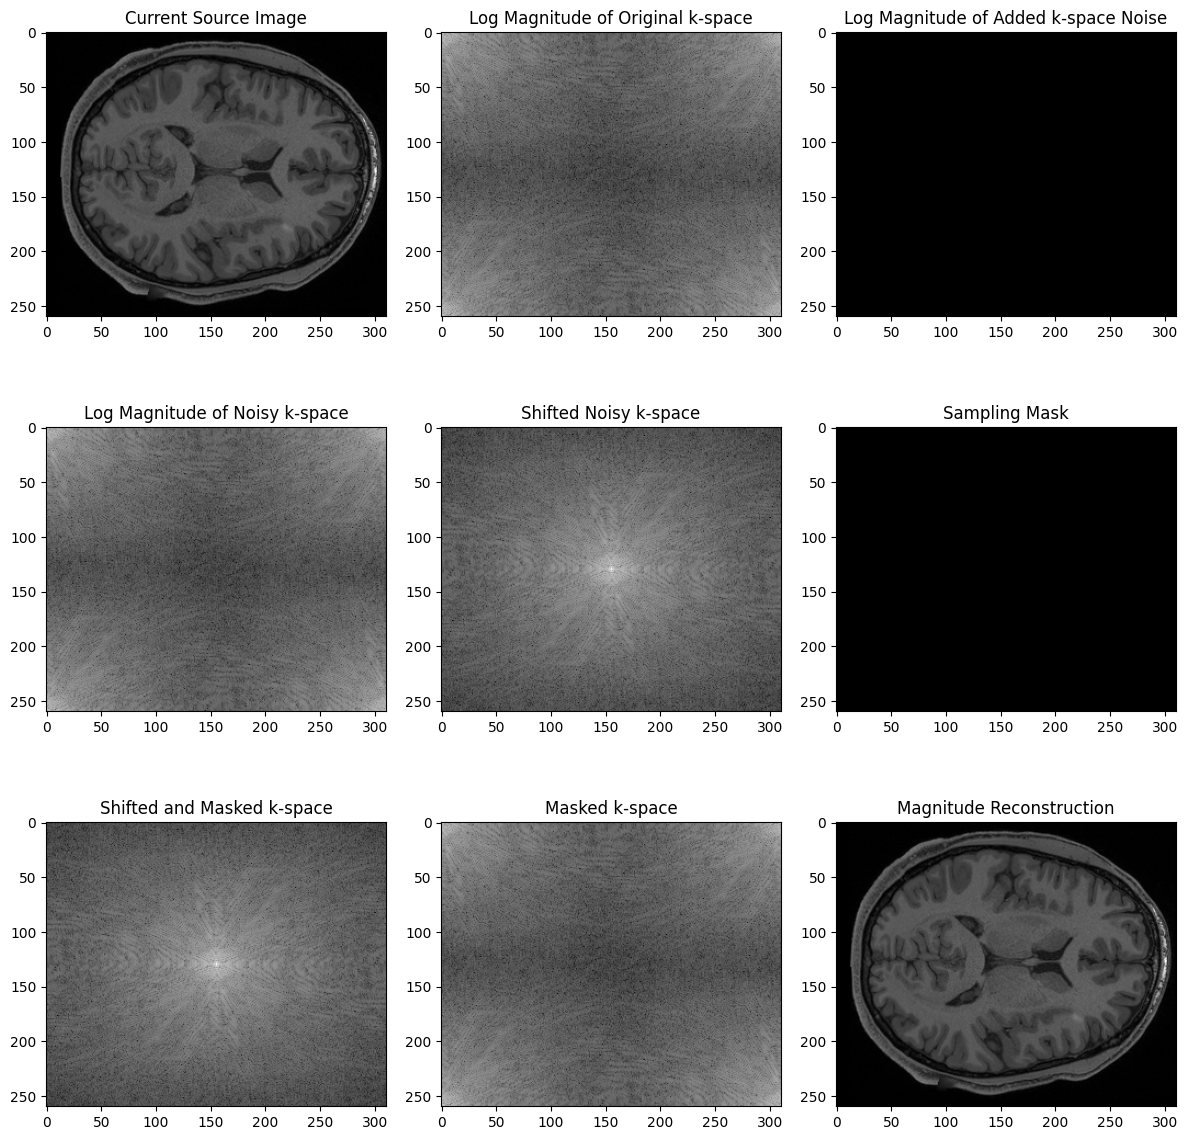

In [28]:
plt.figure(figsize=(12, 12))
plt.subplot(3, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Current Source Image')

plt.subplot(3, 3, 2)
plt.imshow(np.log(np.abs(imagek) + 1e-10), cmap='gray')
plt.title('Log Magnitude of Original k-space')

plt.subplot(3, 3, 3)
plt.imshow(np.log(np.abs(noisek) + 1e-10), cmap='gray')
plt.title('Log Magnitude of Added k-space Noise')

plt.subplot(3, 3, 4)
plt.imshow(np.log(np.abs(imagek_noised) + 1e-10), cmap='gray')
plt.title('Log Magnitude of Noisy k-space')

plt.subplot(3, 3, 5)
plt.imshow(np.log(np.abs(imagek_noised_shifted) + 1e-10), cmap='gray')
plt.title('Shifted Noisy k-space')

plt.subplot(3, 3, 6)
plt.imshow(mask, cmap='gray')
plt.title('Sampling Mask')

plt.subplot(3, 3, 7)
plt.imshow(np.log(np.abs(imagek_noised_shifted_masked) + 1e-10), cmap='gray')
plt.title('Shifted and Masked k-space')

plt.subplot(3, 3, 8)
plt.imshow(np.log(np.abs(imagek_noised_masked) + 1e-10), cmap='gray')
plt.title('Masked k-space')

plt.subplot(3, 3, 9)
plt.imshow(image_undersampled, cmap='gray')
plt.title('Magnitude Reconstruction')

plt.tight_layout()
plt.show()

In [ ]:
iq_results = []
n_metric_images = min(max_metric_images, n_case_images)

for case in generation_cases:
    rng = np.random.default_rng(random_seed)
    mse_values = []
    ssim_values = []
    case_output_filepath = build_reconstructed_filepath(
        case['source_mode'],
        case['lesion_intensity'],
        case['noise_level'],
        case['undersample_factor'],
    )
    case_iq_metrics_filepath = build_iq_metrics_filepath(
        case['source_mode'],
        case['lesion_intensity'],
        case['noise_level'],
        case['undersample_factor'],
    )
    case_images = load_source_images(case['source_mode'], case['lesion_intensity'])

    with open(case_output_filepath, 'wb') as fid:
        for batch_start in range(0, n_case_images, n_batch_images):
            batch_end = min(batch_start + n_batch_images, n_case_images)
            batch_indices = np.arange(batch_start, batch_end)
            batch_reconstructed_images = np.empty((len(batch_indices), *dataset_shape[1:]), dtype=np.float32)

            for local_i, image_i in enumerate(batch_indices):
                source_image = np.asarray(case_images[image_i], dtype=np.float32)
                recon_outputs = reconstruct_from_kspace(
                    source_image,
                    noise_level=case['noise_level'],
                    undersample_factor=case['undersample_factor'],
                    rng=rng,
                )
                reconstructed_image = recon_outputs['image_undersampled'].astype(np.float32)
                batch_reconstructed_images[local_i] = reconstructed_image

                if image_i < n_metric_images:
                    mse_value, ssim_value = compute_image_quality_metrics(source_image, reconstructed_image)
                    mse_values.append(mse_value)
                    ssim_values.append(ssim_value)

            batch_reconstructed_images.tofile(fid)
            print(
                f"{build_case_label(case)} reconstructed images "
                f"{batch_end}/{n_case_images} done"
            )

    mse_values = np.asarray(mse_values, dtype=np.float32)
    ssim_values = np.asarray(ssim_values, dtype=np.float32)
    np.savez(
        case_iq_metrics_filepath,
        mse_mean=float(mse_values.mean()),
        mse_std=float(mse_values.std()),
        ssim_mean=float(ssim_values.mean()),
        ssim_std=float(ssim_values.std()),
        n_images=int(n_metric_images),
    )

    case_iq_result = {
        'case_group': case['case_group'],
        'source_tag': build_source_tag(case['source_mode'], case['lesion_intensity']),
        'noise_level': case['noise_level'],
        'undersample_factor': case['undersample_factor'],
        'mse_mean': float(mse_values.mean()),
        'mse_std': float(mse_values.std()),
        'ssim_mean': float(ssim_values.mean()),
        'ssim_std': float(ssim_values.std()),
        'reconstructed_filepath': case_output_filepath,
    }
    iq_results.append(case_iq_result)
    print(f"Saved reconstructed images to {case_output_filepath}")
    print(f"Saved IQ metrics to {case_iq_metrics_filepath}")
    print(
        f"{build_case_label(case)}: "
        f"MSE={case_iq_result['mse_mean']:.6f} +/- {case_iq_result['mse_std']:.6f}, "
        f"SSIM={case_iq_result['ssim_mean']:.4f} +/- {case_iq_result['ssim_std']:.4f}"
    )

source=lesion_0.10, noise=0.02, undersample=2 metric images 10/10 done
Saved IQ metrics to .\MRI\iq_metrics_source_lesion_0.10_noise_0.02_undersample_2.npz
source=lesion_0.10, noise=0.02, undersample=2: MSE=0.000546 +/- 0.000006, SSIM=0.7874 +/- 0.0079
source=lesion_0.10, noise=0.05, undersample=2 metric images 10/10 done
Saved IQ metrics to .\MRI\iq_metrics_source_lesion_0.10_noise_0.05_undersample_2.npz
source=lesion_0.10, noise=0.05, undersample=2: MSE=0.001173 +/- 0.000008, SSIM=0.6185 +/- 0.0096
source=lesion_0.10, noise=0.10, undersample=2 metric images 10/10 done
Saved IQ metrics to .\MRI\iq_metrics_source_lesion_0.10_noise_0.10_undersample_2.npz
source=lesion_0.10, noise=0.10, undersample=2: MSE=0.003482 +/- 0.000021, SSIM=0.4159 +/- 0.0084
source=lesion_0.10, noise=0.20, undersample=2 metric images 10/10 done
Saved IQ metrics to .\MRI\iq_metrics_source_lesion_0.10_noise_0.20_undersample_2.npz
source=lesion_0.10, noise=0.20, undersample=2: MSE=0.012735 +/- 0.000078, SSIM=0.2089

In [30]:
def noise_level_to_raw_kspace_component_sigma(noise_level, image_shape):
    return float(noise_level * np.sqrt(np.prod(image_shape) / 2.0))

def estimate_image_space_stderr(source_mode, lesion_intensity, noise_level, undersample_factor, image_i=0, n_trials=32, seed=0):
    image = build_source_image(image_i, source_mode, lesion_intensity)
    sampling_mask = mask_lookup[undersample_factor]

    noiseless_outputs = reconstruct_from_kspace(
        image,
        noise_level=0.0,
        undersample_factor=undersample_factor,
    )

    rng = np.random.default_rng(seed)
    complex_errors = np.empty((n_trials, *image.shape), dtype=np.complex64)
    magnitude_errors = np.empty((n_trials, *image.shape), dtype=np.float32)

    for trial_i in range(n_trials):
        noisy_outputs = reconstruct_from_kspace(
            image,
            noise_level=noise_level,
            undersample_factor=undersample_factor,
            rng=rng,
        )
        complex_errors[trial_i] = (
            noisy_outputs['image_undersampled_complex'] - noiseless_outputs['image_undersampled_complex']
        )
        magnitude_errors[trial_i] = (
            noisy_outputs['image_undersampled'] - noiseless_outputs['image_undersampled']
        )

    sample_fraction = float(np.mean(sampling_mask))
    expected_component_stderr = noise_level * np.sqrt(sample_fraction / 2.0)
    raw_kspace_component_sigma = noise_level_to_raw_kspace_component_sigma(noise_level, image.shape)

    return {
        'source_tag': build_source_tag(source_mode, lesion_intensity),
        'noise_level': noise_level,
        'raw_kspace_component_sigma': raw_kspace_component_sigma,
        'undersample_factor': undersample_factor,
        'sample_fraction': sample_fraction,
        'expected_component_stderr': expected_component_stderr,
        'measured_complex_real_stderr_mean': float(complex_errors.real.std(axis=0).mean()),
        'measured_complex_imag_stderr_mean': float(complex_errors.imag.std(axis=0).mean()),
        'measured_magnitude_stderr_mean': float(magnitude_errors.std(axis=0).mean()),
    }

verification_cases = [
    {'source_mode': 'lesion', 'lesion_intensity': 0.10, 'noise_level': 0.00, 'undersample_factor': 2},
    {'source_mode': 'lesion', 'lesion_intensity': 0.10, 'noise_level': 0.00, 'undersample_factor': 4},
    {'source_mode': 'lesion', 'lesion_intensity': 0.10, 'noise_level': 0.02, 'undersample_factor': 2},
    {'source_mode': 'lesion', 'lesion_intensity': 0.10, 'noise_level': 0.10, 'undersample_factor': 2},
    {'source_mode': 'lesion', 'lesion_intensity': 0.10, 'noise_level': 0.30, 'undersample_factor': 2},
    {'source_mode': 'lesion', 'lesion_intensity': 0.20, 'noise_level': 0.10, 'undersample_factor': 2},
]

verification_results = []
for case in verification_cases:
    verification_results.append(
        estimate_image_space_stderr(
            case['source_mode'],
            case['lesion_intensity'],
            case['noise_level'],
            case['undersample_factor'],
            image_i=0,
            n_trials=32,
            seed=random_seed,
        )
    )

for result in verification_results:
    print(
        f"source={result['source_tag']}, normalized_noise={result['noise_level']:.2f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"undersample={result['undersample_factor']}, sample_fraction={result['sample_fraction']:.3f}, "
        f"expected_component_stderr={result['expected_component_stderr']:.4f}, "
        f"real_stderr={result['measured_complex_real_stderr_mean']:.4f}, "
        f"imag_stderr={result['measured_complex_imag_stderr_mean']:.4f}, "
        f"magnitude_stderr={result['measured_magnitude_stderr_mean']:.4f}"
    )

source=lesion_0.10, normalized_noise=0.00, raw_kspace_sigma=0.00, undersample=2, sample_fraction=0.498, expected_component_stderr=0.0000, real_stderr=0.0000, imag_stderr=0.0000, magnitude_stderr=0.0000
source=lesion_0.10, normalized_noise=0.00, raw_kspace_sigma=0.00, undersample=4, sample_fraction=0.251, expected_component_stderr=0.0000, real_stderr=0.0000, imag_stderr=0.0000, magnitude_stderr=0.0000
source=lesion_0.10, normalized_noise=0.02, raw_kspace_sigma=4.02, undersample=2, sample_fraction=0.498, expected_component_stderr=0.0100, real_stderr=0.0097, imag_stderr=0.0098, magnitude_stderr=0.0091
source=lesion_0.10, normalized_noise=0.10, raw_kspace_sigma=20.11, undersample=2, sample_fraction=0.498, expected_component_stderr=0.0499, real_stderr=0.0487, imag_stderr=0.0488, magnitude_stderr=0.0431
source=lesion_0.10, normalized_noise=0.30, raw_kspace_sigma=60.32, undersample=2, sample_fraction=0.498, expected_component_stderr=0.1498, real_stderr=0.1462, imag_stderr=0.1463, magnitude_st